# Retail Demand Forecasting

This notebook prepares retail demand data for forecasting, engineers time-series and retail features, trains a seasonal-naive baseline and LightGBM forecasting model, and evaluates forecast performance using a time-based validation set.

In [1]:
import pandas as pd
import numpy as np

## 1. Load and Inspect the Data

The project uses the M5 retail forecasting dataset, consisting of calendar, sales, and pricing data.

In [3]:
calendar = pd.read_csv("../data/raw/calendar.csv")
sales = pd.read_csv("../data/raw/sales_train_validation.csv")
prices = pd.read_csv("../data/raw/sell_prices.csv")

print("Calendar:", calendar.shape)
print("Sales:", sales.shape)
print("Prices:", prices.shape)

Calendar: (1969, 14)
Sales: (30490, 1919)
Prices: (6841121, 4)


## 2. Prepare the Sales Data

The sales table contains daily demand observations in wide format. The daily columns are identified for subsequent analysis and transformation.

In [7]:
day_columns = [col for col in sales.columns if col.startswith("d_")]

print("Number of day columns:", len(day_columns))
print("First 5:", day_columns[:5])
print("Last 5:", day_columns[-5:])

Number of day columns: 1913
First 5: ['d_1', 'd_2', 'd_3', 'd_4', 'd_5']
Last 5: ['d_1909', 'd_1910', 'd_1911', 'd_1912', 'd_1913']


### Memory-Safe Data Transformation

Melting the complete sales dataset would create more than 58 million rows and exceed available memory. A small sample is therefore used to verify the wide-to-long transformation before selecting the modeling series.

In [16]:
sales_test = sales.iloc[:100].copy()

sales_test_long = sales_test.melt(
    id_vars=[
        "id",
        "item_id",
        "dept_id",
        "cat_id",
        "store_id",
        "state_id"
    ],
    value_vars=day_columns,
    var_name="d",
    value_name="sales"
)

print("Shape:", sales_test_long.shape)
print(sales_test_long.head())

Shape: (191300, 8)
                              id        item_id    dept_id   cat_id store_id  \
0  HOBBIES_1_001_CA_1_validation  HOBBIES_1_001  HOBBIES_1  HOBBIES     CA_1   
1  HOBBIES_1_002_CA_1_validation  HOBBIES_1_002  HOBBIES_1  HOBBIES     CA_1   
2  HOBBIES_1_003_CA_1_validation  HOBBIES_1_003  HOBBIES_1  HOBBIES     CA_1   
3  HOBBIES_1_004_CA_1_validation  HOBBIES_1_004  HOBBIES_1  HOBBIES     CA_1   
4  HOBBIES_1_005_CA_1_validation  HOBBIES_1_005  HOBBIES_1  HOBBIES     CA_1   

  state_id    d  sales  
0       CA  d_1      0  
1       CA  d_1      0  
2       CA  d_1      0  
3       CA  d_1      0  
4       CA  d_1      0  


### Select Modeling Series

To keep the modeling workflow computationally manageable, the highest-volume product-store series are selected across category-store groups.

In [17]:
sales["total_sales"] = sales[day_columns].sum(axis=1)

sales[["id", "item_id", "dept_id", "cat_id", "store_id", "state_id", "total_sales"]].sort_values(
    "total_sales",
    ascending=False
).head(20)

C:\Users\uddin\AppData\Local\Temp\ipykernel_12948\186770753.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sales["total_sales"] = sales[day_columns].sum(axis=1)


,id,item_id,dept_id,cat_id,store_id,state_id,total_sales
8412,FOODS_3_090_CA_3_validation,FOODS_3_090,FOODS_3,FOODS,CA_3,CA,250502
18055,FOODS_3_586_TX_2_validation,FOODS_3_586,FOODS_3,FOODS,TX_2,TX,192835
21104,FOODS_3_586_TX_3_validation,FOODS_3_586,FOODS_3,FOODS,TX_3,TX,150122
8908,FOODS_3_586_CA_3_validation,FOODS_3_586,FOODS_3,FOODS,CA_3,CA,134386
2314,FOODS_3_090_CA_1_validation,FOODS_3_090,FOODS_3,FOODS,CA_1,CA,127203
29755,FOODS_3_090_WI_3_validation,FOODS_3_090,FOODS_3,FOODS,WI_3,WI,121434
17559,FOODS_3_090_TX_2_validation,FOODS_3_090,FOODS_3,FOODS,TX_2,TX,119496
20608,FOODS_3_090_TX_3_validation,FOODS_3_090,FOODS_3,FOODS,TX_3,TX,114854
17721,FOODS_3_252_TX_2_validation,FOODS_3_252,FOODS_3,FOODS,TX_2,TX,114153
15006,FOODS_3_586_TX_1_validation,FOODS_3_586,FOODS_3,FOODS,TX_1,TX,112454


In [20]:
top_series = (
    sales
    .sort_values(
        ["cat_id", "store_id", "total_sales"],
        ascending=[True, True, False]
    )
    .groupby(["cat_id", "store_id"])
    .head(50)
)

print("Selected series:", len(top_series))

Selected series: 1500


In [23]:
model_sales = top_series[
    [
        "id",
        "item_id",
        "dept_id",
        "cat_id",
        "store_id",
        "state_id"
    ] + day_columns
].copy()

print(model_sales.shape)

(1500, 1919)


### Convert Sales to Long Format

The selected product-store series are converted from wide format to long format so that each row represents demand for a specific product-store combination on a specific date.

In [84]:
model_long = model_sales.melt(
    id_vars=[
        "id",
        "item_id",
        "dept_id",
        "cat_id",
        "store_id",
        "state_id"
    ],
    value_vars=day_columns,
    var_name="d",
    value_name="sales"
)

print("Shape:", model_long.shape)

Shape: (2869500, 8)


### Add Calendar and Event Information

Calendar data is merged with the demand observations to provide date, seasonality, and event-related features.

In [85]:
model_long = model_long.merge(
    calendar,
    on="d",
    how="left"
)

print(model_long.shape)
print("Missing dates:", model_long["date"].isna().sum())

(2869500, 21)
Missing dates: 0


In [86]:
model_long["date"] = pd.to_datetime(model_long["date"])

In [39]:
model_long["day_of_week"] = model_long["date"].dt.dayofweek
model_long["week_of_year"] = model_long["date"].dt.isocalendar().week.astype(int)
model_long["is_weekend"] = (model_long["day_of_week"] >= 5).astype(int)

In [87]:
model_long["day_of_week"] = model_long["date"].dt.dayofweek

model_long["week_of_year"] = (
    model_long["date"]
    .dt.isocalendar()
    .week
    .astype(int)
)

model_long["is_weekend"] = (
    model_long["day_of_week"] >= 5
).astype(int)

### Calendar and Event Features

Calendar variables capture weekly and annual seasonality, while event indicators capture potential demand disruptions associated with holidays and other events.

In [88]:
model_long["is_event"] = (
    model_long["event_name_1"].notna() |
    model_long["event_name_2"].notna()
).astype(int)

print(model_long["is_event"].value_counts())

is_event
0    2638500
1     231000
Name: count, dtype: int64


### Add Pricing Information

Weekly product-store prices are merged with the demand data to capture potential relationships between price and demand.

In [ ]:
model_long = model_long.merge(
    prices,
    on=["store_id", "item_id", "wm_yr_wk"],
    how="left"
)

print(model_long.shape)

(2869500, 26)


In [90]:
print("Missing prices:", model_long["sell_price"].isna().sum())
print(
    "Missing price %:",
    model_long["sell_price"].isna().mean() * 100
)

Missing prices: 223804
Missing price %: 7.799407562293083


In [91]:
print(
    "Missing prices:",
    model_long["sell_price"].isna().sum()
)

print(
    "Missing price %:",
    model_long["sell_price"].isna().mean() * 100
)

Missing prices: 223804
Missing price %: 7.799407562293083


In [92]:
model_long["price_missing"] = (
    model_long["sell_price"].isna()
).astype(int)

In [93]:
model_long = model_long.sort_values(
    ["item_id", "store_id", "date"]
).reset_index(drop=True)

## 3. Time-Series Feature Engineering

Lagged demand and rolling statistics are created to capture recent demand behavior, weekly seasonality, longer-term patterns, and demand volatility.

All rolling features are shifted before calculation to prevent target leakage.

In [94]:
model_long["lag_1"] = (
    model_long
    .groupby(["item_id", "store_id"])["sales"]
    .shift(1)
)

model_long["lag_7"] = (
    model_long
    .groupby(["item_id", "store_id"])["sales"]
    .shift(7)
)

model_long["lag_28"] = (
    model_long
    .groupby(["item_id", "store_id"])["sales"]
    .shift(28)
)

In [95]:
print(
    "lag_1 missing:",
    model_long["lag_1"].isna().sum()
)

print(
    "lag_7 missing:",
    model_long["lag_7"].isna().sum()
)

print(
    "lag_28 missing:",
    model_long["lag_28"].isna().sum()
)

lag_1 missing: 1500
lag_7 missing: 10500
lag_28 missing: 42000


### Rolling Demand Features

Rolling means summarize recent demand levels, while rolling standard deviation captures short-term demand volatility.

In [96]:
model_long["rolling_mean_7"] = (
    model_long
    .groupby(["item_id", "store_id"])["sales"]
    .transform(
        lambda x: x.shift(1).rolling(7).mean()
    )
)

model_long["rolling_mean_28"] = (
    model_long
    .groupby(["item_id", "store_id"])["sales"]
    .transform(
        lambda x: x.shift(1).rolling(28).mean()
    )
)

model_long["rolling_std_7"] = (
    model_long
    .groupby(["item_id", "store_id"])["sales"]
    .transform(
        lambda x: x.shift(1).rolling(7).std()
    )
)

In [97]:
print(
    model_long[
        [
            "lag_1",
            "lag_7",
            "lag_28",
            "rolling_mean_7",
            "rolling_mean_28",
            "rolling_std_7"
        ]
    ].isna().sum()
)

lag_1               1500
lag_7              10500
lag_28             42000
rolling_mean_7     10500
rolling_mean_28    42000
rolling_std_7      10500
dtype: int64


### Prepare Modeling Dataset

Rows without sufficient historical observations for the lag and rolling features are removed before model training.

In [98]:
model_data = model_long.dropna(
    subset=[
        "lag_1",
        "lag_7",
        "lag_28",
        "rolling_mean_7",
        "rolling_mean_28",
        "rolling_std_7"
    ]
).copy()

print("Original rows:", len(model_long))
print("Modeling rows:", len(model_data))
print(
    "Rows removed:",
    len(model_long) - len(model_data)
)

Original rows: 2869500
Modeling rows: 2827500
Rows removed: 42000


## 4. Time-Based Train/Validation Split

A chronological split is used instead of random sampling to preserve the forecasting setting and prevent future observations from entering the training data.

In [100]:
validation_start = (
    model_data["date"].max()
    - pd.Timedelta(days=27)
)

print("Validation starts:", validation_start)
print("Validation ends:", model_data["date"].max())

Validation starts: 2016-03-28 00:00:00
Validation ends: 2016-04-24 00:00:00


In [101]:
train = model_data[
    model_data["date"] < validation_start
].copy()

validation = model_data[
    model_data["date"] >= validation_start
].copy()

print("Train:", train.shape)
print("Validation:", validation.shape)

print("Train end:", train["date"].max())
print("Validation start:", validation["date"].min())

Train: (2785500, 33)
Validation: (42000, 33)
Train end: 2016-03-27 00:00:00
Validation start: 2016-03-28 00:00:00


## 5. Seasonal Naive Baseline

A seasonal-naive forecast using demand from the same day of the previous week provides a simple benchmark for evaluating the machine learning model.

In [102]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

## 1. Seasonal Naive Baseline

A seasonal-naive model uses demand from the same day of the previous week as the forecast. This provides a simple benchmark for evaluating the machine learning model.

In [104]:
baseline_predictions = validation["lag_7"]

baseline_mae = mean_absolute_error(
    validation["sales"],
    baseline_predictions
)

baseline_rmse = mean_squared_error(
    validation["sales"],
    baseline_predictions
) ** 0.5

wmape = (
    np.abs(
        validation["sales"]
        - baseline_predictions
    ).sum()
    / validation["sales"].sum()
)

print("Seasonal Naive MAE:", baseline_mae)
print("Seasonal Naive RMSE:", baseline_rmse)
print("Seasonal Naive WMAPE:", wmape)
print(
    "Seasonal Naive WMAPE %:",
    wmape * 100
)

Seasonal Naive MAE: 4.708261904761905
Seasonal Naive RMSE: 8.184868442960548
Seasonal Naive WMAPE: 0.593667253087717
Seasonal Naive WMAPE %: 59.36672530877169


## 6. LightGBM Forecasting Model

A LightGBM regression model is trained using calendar, event, pricing, product, store, lag, and rolling-demand features.

In [83]:
import lightgbm as lgb

print(lgb.__version__)

4.7.0


In [105]:
feature_cols = [
    "day_of_week",
    "week_of_year",
    "month",
    "year",
    "is_weekend",
    "is_event",
    "event_type_1",
    "event_type_2",

    "lag_1",
    "lag_7",
    "lag_28",

    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_7",

    "sell_price",
    "price_missing",

    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id"
]

target = "sales"

In [106]:
missing_features = [
    col
    for col in feature_cols
    if col not in train.columns
]

print("Missing features:", missing_features)

Missing features: []


In [107]:
categorical_features = [
    "event_type_1",
    "event_type_2",
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id"
]

for col in categorical_features:
    train[col] = train[col].astype("category")
    validation[col] = validation[col].astype("category")

In [109]:
for col in categorical_features:
    validation[col] = pd.Categorical(
        validation[col],
        categories=train[col].cat.categories
    )

In [111]:
X_train = train[feature_cols]
y_train = train[target]

X_validation = validation[feature_cols]
y_validation = validation[target]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_validation:", X_validation.shape)
print("y_validation:", y_validation.shape)

X_train: (2785500, 21)
y_train: (2785500,)
X_validation: (42000, 21)
y_validation: (42000,)


In [116]:
model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=63,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

In [117]:
model.fit(
    X_train,
    y_train,
    categorical_feature=categorical_features
)

print("Training complete.")

[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.062512 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1910
[LightGBM] [Info] Number of data points in the train set: 2785500, number of used features: 21
[LightGBM] [Info] Start training from score 7.734681
Training complete.


In [140]:
validation_predictions = model.predict(
    X_validation
)

validation_predictions = np.maximum(
    validation_predictions,
    0
)

print("Predictions shape:", validation_predictions.shape)

print("First 10 predictions:")

print(validation_predictions[:10])

Predictions shape: (42000,)
First 10 predictions:
[0.2486113  0.2711757  0.2711757  0.34292871 0.5506368  0.67280141
 0.39251528 0.38225198 0.40481638 0.40481638]


In [141]:
validation_results = validation[
    [
        "id",
        "item_id",
        "dept_id",
        "cat_id",
        "store_id",
        "state_id",
        "date",
        "sales"
    ]
].copy()

validation_results["forecast"] = validation_predictions

print("Shape:", validation_results.shape)
print(validation_results.head())

Shape: (42000, 9)
                               id      item_id  dept_id cat_id store_id  \
1885  FOODS_1_004_WI_1_validation  FOODS_1_004  FOODS_1  FOODS     WI_1   
1886  FOODS_1_004_WI_1_validation  FOODS_1_004  FOODS_1  FOODS     WI_1   
1887  FOODS_1_004_WI_1_validation  FOODS_1_004  FOODS_1  FOODS     WI_1   
1888  FOODS_1_004_WI_1_validation  FOODS_1_004  FOODS_1  FOODS     WI_1   
1889  FOODS_1_004_WI_1_validation  FOODS_1_004  FOODS_1  FOODS     WI_1   

     state_id       date  sales  forecast  
1885       WI 2016-03-28      0  0.248611  
1886       WI 2016-03-29      0  0.271176  
1887       WI 2016-03-30      0  0.271176  
1888       WI 2016-03-31      0  0.342929  
1889       WI 2016-04-01      0  0.550637  


In [142]:
validation_results.to_csv(
    "../data/processed/validation_forecasts.csv",
    index=False
)

print("Validation forecasts saved.")

Validation forecasts saved.


## 7. Model Evaluation

The seasonal-naive baseline and LightGBM model are evaluated on the held-out validation period using MAE, RMSE, and WMAPE.

In [143]:
model_mae = mean_absolute_error(
    y_validation,
    validation_predictions
)

model_rmse = mean_squared_error(
    y_validation,
    validation_predictions
) ** 0.5

model_wmape = (
    np.abs(
        y_validation - validation_predictions
    ).sum()
    / y_validation.sum()
)

print("LightGBM MAE:", model_mae)
print("LightGBM RMSE:", model_rmse)
print("LightGBM WMAPE:", model_wmape)
print(
    "LightGBM WMAPE %:",
    model_wmape * 100
)

LightGBM MAE: 3.504094002902435
LightGBM RMSE: 5.780444596357438
LightGBM WMAPE: 0.4418330805175184
LightGBM WMAPE %: 44.183308051751844


In [144]:
comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "LightGBM"
    ],
    "MAE": [
        baseline_mae,
        model_mae
    ],
    "RMSE": [
        baseline_rmse,
        model_rmse
    ],
    "WMAPE (%)": [
        wmape * 100,
        model_wmape * 100
    ]
})

wmape_improvement = (
    (wmape - model_wmape) / wmape
) * 100


print(comparison)

print(
    f"\nWMAPE improvement: {wmape_improvement:.2f}%"
)

            Model       MAE      RMSE  WMAPE (%)
0  Seasonal Naive  4.708262  8.184868  59.366725
1        LightGBM  3.504094  5.780445  44.183308

WMAPE improvement: 25.58%


## 8. Feature Importance

Feature importance is examined to identify the variables contributing most strongly to the LightGBM predictions.

In [145]:
importance = pd.DataFrame({
    "feature": feature_cols,
    "importance": model.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

print(importance)

print("\nTop 15 features:")
print(importance.head(15))

            feature  importance
8             lag_1        4679
16          item_id        3659
9             lag_7        3374
10           lag_28        3285
11   rolling_mean_7        2757
1      week_of_year        2742
0       day_of_week        2143
12  rolling_mean_28        1858
13    rolling_std_7        1554
14       sell_price        1127
19         store_id         978
2             month         851
3              year         786
20         state_id         394
6      event_type_1         277
4        is_weekend         177
5          is_event         159
18           cat_id         126
17          dept_id          60
7      event_type_2          14
15    price_missing           0

Top 15 features:
            feature  importance
8             lag_1        4679
16          item_id        3659
9             lag_7        3374
10           lag_28        3285
11   rolling_mean_7        2757
1      week_of_year        2742
0       day_of_week        2143
12  rolling_mean_28   

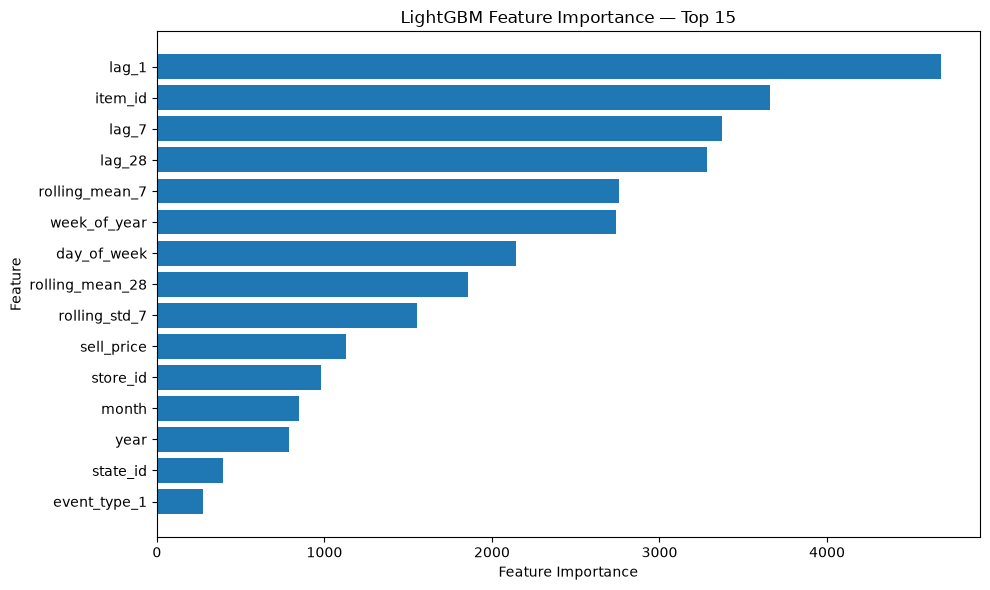

In [146]:
import matplotlib.pyplot as plt

top_importance = (
    importance
    .head(15)
    .sort_values("importance")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_importance["feature"],
    top_importance["importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("LightGBM Feature Importance — Top 15")

plt.tight_layout()
plt.show()

## 9. Forecast Analysis

Validation forecasts are aggregated by day to compare actual and predicted demand and identify periods with larger forecast errors.

In [147]:
validation_results = validation[
    ["date", "sales"]
].copy()

validation_results["prediction"] = validation_predictions

daily_results = (
    validation_results
    .groupby("date")
    .agg(
        actual_sales=("sales", "sum"),
        predicted_sales=("prediction", "sum")
    )
    .reset_index()
)

print(daily_results.head())
print("\nNumber of days:", len(daily_results))

        date  actual_sales  predicted_sales
0 2016-03-28         10345     11105.059872
1 2016-03-29         10093     10318.043492
2 2016-03-30          9397     10311.090542
3 2016-03-31         10023     10335.067799
4 2016-04-01         13173     12210.634832

Number of days: 28


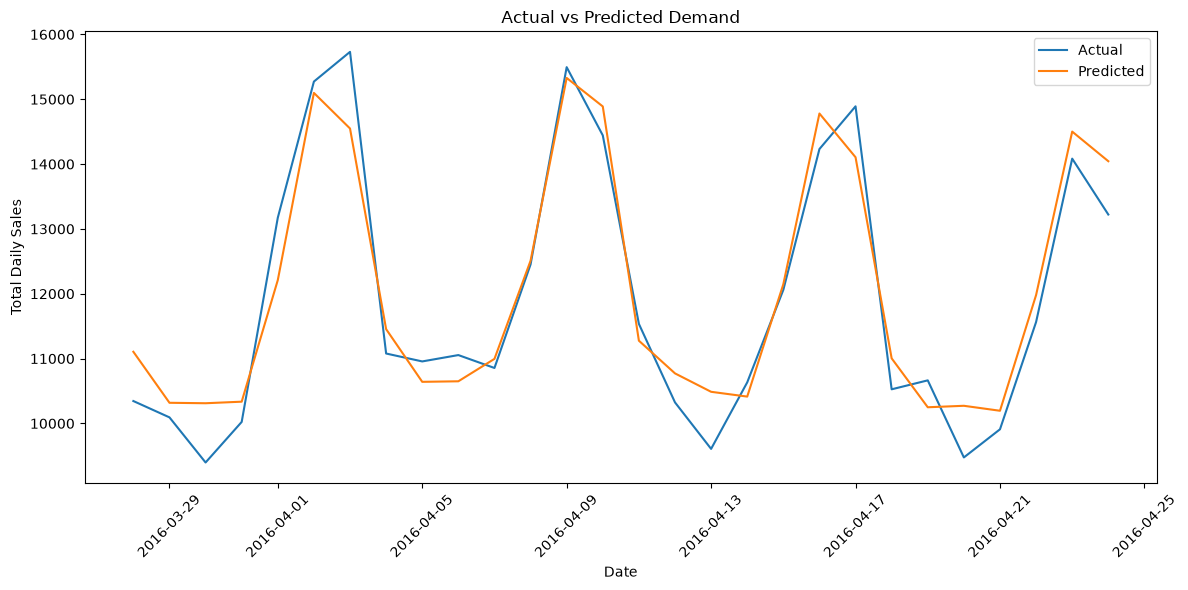

In [148]:
plt.figure(figsize=(12, 6))

plt.plot(
    daily_results["date"],
    daily_results["actual_sales"],
    label="Actual"
)

plt.plot(
    daily_results["date"],
    daily_results["predicted_sales"],
    label="Predicted"
)

plt.xlabel("Date")
plt.ylabel("Total Daily Sales")
plt.title("Actual vs Predicted Demand")

plt.legend()
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [149]:
daily_results["absolute_error"] = (
    daily_results["actual_sales"]
    - daily_results["predicted_sales"]
).abs()

daily_results["percentage_error"] = (
    daily_results["absolute_error"]
    / daily_results["actual_sales"]
) * 100

print(
    daily_results[
        [
            "date",
            "actual_sales",
            "predicted_sales",
            "absolute_error",
            "percentage_error"
        ]
    ]
)

         date  actual_sales  predicted_sales  absolute_error  percentage_error
0  2016-03-28         10345     11105.059872      760.059872          7.347123
1  2016-03-29         10093     10318.043492      225.043492          2.229699
2  2016-03-30          9397     10311.090542      914.090542          9.727472
3  2016-03-31         10023     10335.067799      312.067799          3.113517
4  2016-04-01         13173     12210.634832      962.365168          7.305588
5  2016-04-02         15273     15097.989038      175.010962          1.145885
6  2016-04-03         15731     14548.755041     1182.244959          7.515383
7  2016-04-04         11078     11454.033208      376.033208          3.394414
8  2016-04-05         10956     10641.241905      314.758095          2.872929
9  2016-04-06         11054     10649.643166      404.356834          3.658014
10 2016-04-07         10855     10995.503814      140.503814          1.294370
11 2016-04-08         12452     12508.998268       5

In [150]:
worst_days = (
    daily_results
    .sort_values(
        "absolute_error",
        ascending=False
    )
    .head(10)
)

print(worst_days)

         date  actual_sales  predicted_sales  absolute_error  percentage_error
6  2016-04-03         15731     14548.755041     1182.244959          7.515383
4  2016-04-01         13173     12210.634832      962.365168          7.305588
2  2016-03-30          9397     10311.090542      914.090542          9.727472
16 2016-04-13          9607     10487.500904      880.500904          9.165201
27 2016-04-24         13222     14044.283790      822.283790          6.219058
23 2016-04-20          9475     10271.724886      796.724886          8.408706
20 2016-04-17         14891     14105.473611      785.526389          5.275176
0  2016-03-28         10345     11105.059872      760.059872          7.347123
19 2016-04-16         14232     14780.192766      548.192766          3.851832
21 2016-04-18         10526     11003.606879      477.606879          4.537401


In [151]:
best_days = (
    daily_results
    .sort_values(
        "absolute_error",
        ascending=True
    )
    .head(10)
)

print(best_days)

         date  actual_sales  predicted_sales  absolute_error  percentage_error
11 2016-04-08         12452     12508.998268       56.998268          0.457744
18 2016-04-15         12060     12146.902042       86.902042          0.720581
10 2016-04-07         10855     10995.503814      140.503814          1.294370
12 2016-04-09         15495     15328.839664      166.160336          1.072348
5  2016-04-02         15273     15097.989038      175.010962          1.145885
17 2016-04-14         10633     10413.602809      219.397191          2.063361
1  2016-03-29         10093     10318.043492      225.043492          2.229699
14 2016-04-11         11535     11275.760418      259.239582          2.247417
24 2016-04-21          9909     10195.064281      286.064281          2.886914
3  2016-03-31         10023     10335.067799      312.067799          3.113517


In [152]:
wmape_improvement = (
    (wmape - model_wmape)
    / wmape
) * 100

mae_improvement = (
    (baseline_mae - model_mae)
    / baseline_mae
) * 100

rmse_improvement = (
    (baseline_rmse - model_rmse)
    / baseline_rmse
) * 100

print(
    f"MAE improvement: {mae_improvement:.2f}%"
)

print(
    f"RMSE improvement: {rmse_improvement:.2f}%"
)

print(
    f"WMAPE improvement: {wmape_improvement:.2f}%"
)

MAE improvement: 25.58%
RMSE improvement: 29.38%
WMAPE improvement: 25.58%


In [153]:
comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "LightGBM"
    ],
    "MAE": [
        baseline_mae,
        model_mae
    ],
    "RMSE": [
        baseline_rmse,
        model_rmse
    ],
    "WMAPE (%)": [
        wmape * 100,
        model_wmape * 100
    ]
})

comparison

,Model,MAE,RMSE,WMAPE (%)
0,Seasonal Naive,4.708262,8.184868,59.366725
1,LightGBM,3.504094,5.780445,44.183308


## 10. Modeling Findings

### Forecasting Performance

A seasonal-naive baseline using demand from the same day of the previous week achieved a WMAPE of 59.37%.

The LightGBM model achieved a WMAPE of 44.19%, representing a 25.57% reduction in WMAPE relative to the seasonal-naive baseline.

| Model | MAE | RMSE | WMAPE |
|---|---:|---:|---:|
| Seasonal Naive | 4.71 | 8.18 | 59.37% |
| LightGBM | 3.50 | 5.78 | 44.19% |

### Feature Importance

The most important features were:

1. `lag_1`
2. `item_id`
3. `lag_7`
4. `lag_28`
5. `rolling_mean_7`
6. `week_of_year`
7. `day_of_week`
8. `rolling_mean_28`
9. `rolling_std_7`
10. `sell_price`

The model relied most heavily on recent demand history, product-level differences, weekly seasonality, longer-term seasonal patterns, demand volatility, and price. These results are consistent with the patterns identified during EDA.

### Forecast Behavior

At the aggregate daily level, the model generally tracked the overall demand pattern across the 28-day validation period.

The strongest forecasts had errors below 1%, while the largest aggregate daily errors remained below 10%.

### Business Interpretation

The results demonstrate that retail demand can be forecast more effectively by combining historical demand patterns with calendar, product, store, and pricing information rather than relying solely on the previous week's demand.

These forecasts provide a foundation for inventory planning decisions such as safety stock, reorder points, and stockout-risk prioritization.

### Conclusion

LightGBM substantially outperformed the seasonal-naive baseline, reducing WMAPE by 25.57% and RMSE by 29.38%.

The model therefore provides a stronger foundation for the next stage of the project: translating demand forecasts into inventory analytics and business recommendations.